# Topic 11: Data Cleaning

> 'Garbage in, garbage out.' - Cleaning data is 70-80% of real data work.

**Topics:** Detect missing values - Duplicates - Text formatting - Outliers - Normalisation - Encoding


## 1. Build a Messy Dataset


In [ ]:
import pandas as pd, numpy as np

df = pd.DataFrame({
    "Name":   ["Alice","bob","CHARLIE","diana","  Eve  ","Frank","Alice",None],
    "Age":    [25, 30, -5, 28, 200, 35, 25, np.nan],
    "Salary": [45000,72000,38000,np.nan,55000,90000,45000,61000],
    "Score":  [85,92,78,95,88,91,85,200],
    "City":   ["Accra","kumasi","Tamale","ACCRA","Accra","Kumasi","Accra",np.nan],
})
print(df.to_string())
print("\nMissing values:")
print(df.isnull().sum())

## 2. Remove Duplicates


In [ ]:
print("Before:", len(df))
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("After:", len(df))

## 3. Fix Text Formatting


In [ ]:
df["Name"] = df["Name"].str.strip().str.title().fillna("Unknown")
df["City"] = df["City"].str.strip().str.title()
print(df[["Name","City"]])

## 4. Outlier Detection


In [ ]:
print("Age outliers (outside 0–100):")
print(df[(df["Age"]<0)|(df["Age"]>100)][["Name","Age"]])

print("\nScore outliers (outside 0–100):")
print(df[(df["Score"]<0)|(df["Score"]>100)][["Name","Score"]])

# Clip to valid range
df["Age"]   = df["Age"].clip(0, 100)
df["Score"] = df["Score"].clip(0, 100)
print("\nAfter clipping:")
print(df[["Name","Age","Score"]])

## 5. Fill Missing Values


In [ ]:
df["Age"]    = df["Age"].fillna(df["Age"].median())
df["Salary"] = df["Salary"].fillna(df["Salary"].median())
df["City"]   = df["City"].fillna(df["City"].mode()[0])
print("Missing values after filling:")
print(df.isnull().sum())

## 6. Data Normalisation


In [ ]:
def min_max(s): return (s - s.min()) / (s.max() - s.min())
def z_score(s): return (s - s.mean()) / s.std()

df["Salary_MinMax"] = min_max(df["Salary"]).round(3)
df["Salary_ZScore"] = z_score(df["Salary"]).round(3)

print(df[["Name","Salary","Salary_MinMax","Salary_ZScore"]].to_string(index=False))

## ✅ Final Clean Dataset


In [ ]:
print("Final clean dataset:")
print(df[["Name","Age","Salary","City","Score"]].to_string(index=False))

# Practical Data Cleaning

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## Step 2: Load the data
df = sns.load_dataset("titanic")

In [3]:
# Display the first rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Step 3: Understand the data

In [4]:
# How mmany rows and columns are there in my data
# Shape
df.shape

(891, 15)

In [5]:
# What are the column names
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [6]:
# Data types
df.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [7]:
# General information 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


# Step 4: Summary Statistics

In [8]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# For categorical columns
df.describe(include = "object")

,sex,embarked,who,embark_town,alive
count,891,889,891,889,891
unique,2,3,3,3,2
top,male,S,man,Southampton,no
freq,577,644,537,644,549


# Step 5: Check missing values

In [10]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [11]:
# Percentages of missing values
(df.isnull().mean()*100).round(2)

survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64

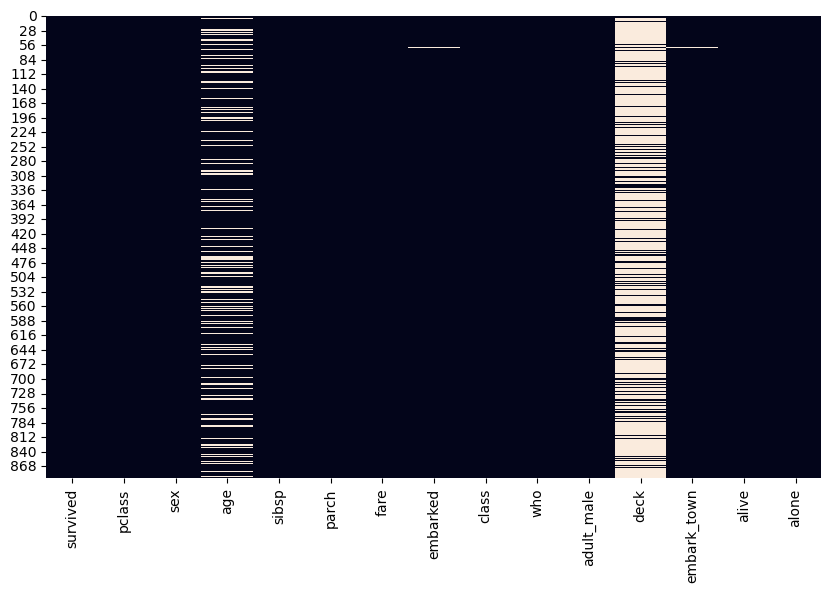

In [12]:
# Visualize
plt.figure(figsize = (10, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.show()

# Step 6: Decide how to handle the missing Values


In [13]:
# 1. Remove rows that have missing values
df.dropna(inplace = True)

In [14]:
df.shape

(182, 15)

In [15]:
# Re-reading the data

df = sns.load_dataset("titanic")

In [16]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [17]:
# Option 2: Remove columns 
df.drop(columns=["deck"], inplace = True)
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
embark_town      2
alive            0
alone            0
dtype: int64

In [18]:
# 3. Fill the missing values
# Mean
# df['age'].fillna(df['age'].mean(), inplace = True)

# Median
df['age'].fillna(df['age'].median(), inplace = True)



C:\Users\Admin\AppData\Local\Temp\ipykernel_14052\1696690727.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace = True)


In [19]:
# 4: Fill categrical Values
# Using mode

df['embark_town'].fillna(
    df['embark_town'].mode()[0],
    inplace = True
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_14052\2770728924.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['embark_town'].fillna(


In [20]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

# Step 7: Check Duplicates

In [21]:
# Count the duplicates
df.duplicated().sum()

116

In [22]:
# Display the duplicates
df[df.duplicated()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
47,1,3,female,28.0,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True
55,1,1,male,28.0,0,0,35.5000,S,First,man,True,Southampton,yes,True
76,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
77,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
87,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,0,3,male,26.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
877,0,3,male,19.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
878,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,Southampton,no,True


In [23]:
# Remove the duplicates
df.drop_duplicates(inplace = True)

In [24]:
df.shape

(775, 14)

# Step 8: Fix the Data Types

In [25]:
# Example converting age column to numerical data type
df['age'] = pd.to_numeric(df['age'])

In [26]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 775 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     775 non-null    int64   
 1   pclass       775 non-null    int64   
 2   sex          775 non-null    object  
 3   age          775 non-null    float64 
 4   sibsp        775 non-null    int64   
 5   parch        775 non-null    int64   
 6   fare         775 non-null    float64 
 7   embarked     773 non-null    object  
 8   class        775 non-null    category
 9   who          775 non-null    object  
 10  adult_male   775 non-null    bool    
 11  embark_town  775 non-null    object  
 12  alive        775 non-null    object  
 13  alone        775 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), object(5)
memory usage: 75.1+ KB


In [28]:
# convert categories
df['sex'] = df['sex'].astype("category")

In [29]:
df.dtypes

survived          int64
pclass            int64
sex            category
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
embark_town      object
alive            object
alone              bool
dtype: object

# Step 9: Fix text columns

In [30]:
df['sex'].unique()

['male', 'female']
Categories (2, object): ['female', 'male']

In [31]:
''' if the data example was

Male
male
 male
MALE
'''
# Example
df['sex'] = (
    df['sex']
        .str.lower()
        .str.strip()
)

In [32]:
df['sex'].unique()

array(['male', 'female'], dtype=object)

In [33]:
df['sex'].value_counts()

sex
male      483
female    292
Name: count, dtype: int64

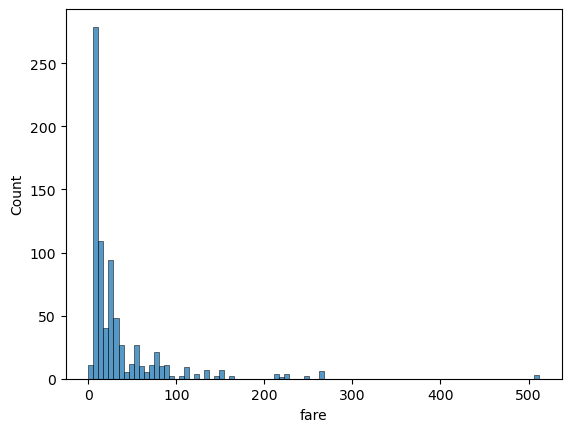

In [34]:
# Step: Detect Outliers
# Histogram
sns.histplot(df['fare'])
plt.show()

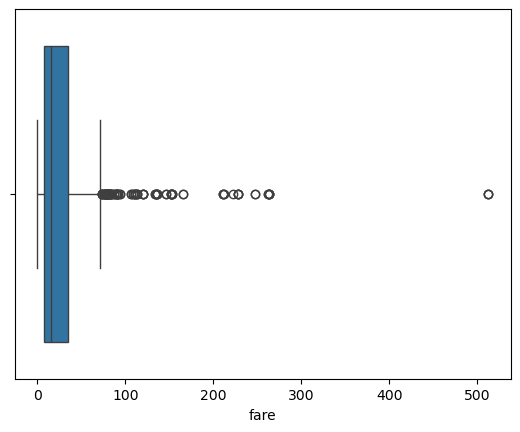

In [35]:
# use box plot
sns.boxplot(x = df['fare'])
plt.show()

In [36]:
# Remove outlier using IQR
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

df = df[
    (df['fare']>=lower) &
    (df['fare']<=upper)
]

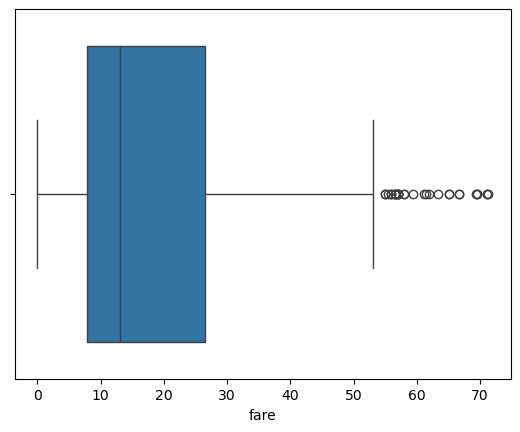

In [37]:
sns.boxplot(x = df['fare'])
plt.show()

# Check impossible values


In [38]:
# Negative ages
df[df["age"]<0]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone


In [39]:
# Check for fare less than 0
df[df["fare"]<0]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone


# Check for consistency

In [40]:
df['sex'].value_counts()

sex
male      443
female    230
Name: count, dtype: int64

# Feature Validation 


In [41]:
# Minimum value of age
df['age'].min()

0.42

In [42]:
df['age'].max()

80.0

# Final Check 

In [43]:
df .info()

<class 'pandas.core.frame.DataFrame'>
Index: 673 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     673 non-null    int64   
 1   pclass       673 non-null    int64   
 2   sex          673 non-null    object  
 3   age          673 non-null    float64 
 4   sibsp        673 non-null    int64   
 5   parch        673 non-null    int64   
 6   fare         673 non-null    float64 
 7   embarked     673 non-null    object  
 8   class        673 non-null    category
 9   who          673 non-null    object  
 10  adult_male   673 non-null    bool    
 11  embark_town  673 non-null    object  
 12  alive        673 non-null    object  
 13  alone        673 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), object(5)
memory usage: 65.2+ KB


In [44]:
# Statistical Analysis
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,673.000000,673.000000,673.000000,673.000000,673.000000,673.000000
mean,0.365527,2.427935,28.950223,0.509658,0.396731,19.496087
std,0.481936,0.762549,13.604993,1.022214,0.837258,14.809501
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.000000,0.000000,0.000000,7.895800
50%,0.000000,3.000000,28.000000,0.000000,0.000000,13.000000
75%,1.000000,3.000000,36.000000,1.000000,0.000000,26.550000
max,1.000000,3.000000,80.000000,8.000000,6.000000,71.283300


In [46]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

# Save the clearn Data

In [47]:
df.to_csv("clean_titanic.csv", index = False)

# Practical exercise
1. `tips` - Handle the missing values, check the data types inspect the numerical distributions
2. `penguins` - handle the missing values in measurement, standardize catergorical coluns, examine the outliers in the datasets
3. `diamonds` - look for duplicates, inspect categorical inconsistencies, analyze outliers in price and carat
4. `flights` - convert the columns to appropriate types and validate the data
5. `exercise` - inspect categories, missing values and duplicate records